In [19]:
!pip uninstall --break-system-packages numba -y
!pip install --break-system-packages PyMPDATA numba==0.61.2

Found existing installation: numba 0.66.0
Uninstalling numba-0.66.0:
  Successfully uninstalled numba-0.66.0
Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 15.8 MB/s eta 0:00:0031m31.4 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 MB 21.1 MB/s eta 0:00:00m eta 0:00:010:01
  Attempting uninstall: llvmlite
    Found existing installation: llvmlite 0.48.0
    Uninstalling llvmlite-0.48.0:
      Successfully uninstalled llvmlite-0.48.0━━━━━━━━ 0/2 [llvmlite]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [numba]━━━━━ 1/2 [numba]


In [11]:
import PyMPDATA as pymd
from PyMPDATA import ScalarField, VectorField, Options, Solver, boundary_conditions, Stepper
print(pymd.__file__)

/home/stud2023/3janiak/.local/lib/python3.13/site-packages/PyMPDATA/__init__.py


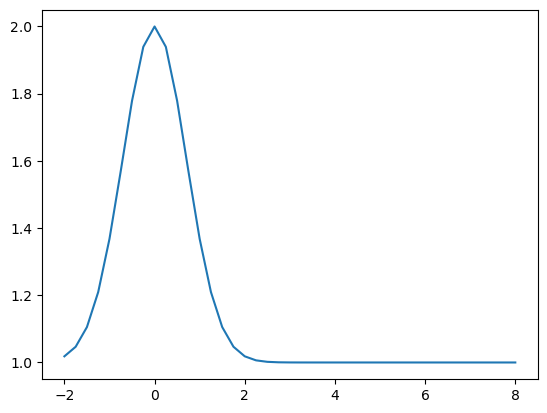

In [26]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-2, 8, 41)
y = np.exp(-x**2)+1

plt.plot(x, y)
plt.show()

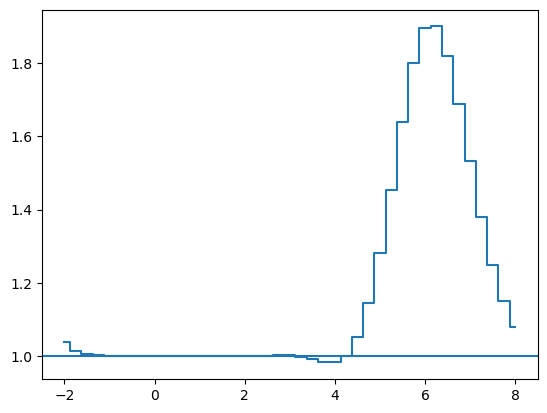

In [28]:
common = {'halo': (options := Options(nonoscillatory = False)).n_halo, 'boundary_conditions': (boundary_conditions.Periodic(), )}
advector = VectorField(**common, data = (np.full(x.size+1, 0.25), ))
advectee = ScalarField(**common, data = y)

solver = Solver(advectee = advectee, advector = advector, stepper = Stepper(n_dims = 1, options = options))
solver.advance(n_steps = 100)
               
plt.step(x, solver.advectee.get(), where = 'mid')
plt.axhline(1)
plt.show()